In [9]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

In [1]:
# Part 0 — Shared Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay
)

rng = np.random.default_rng(42)
n = 500

df = pd.DataFrame({
    "demand": rng.integers(50, 151, n),
    "supply": rng.integers(45, 141, n),
    "distance_km": rng.uniform(1, 15, n).round(1),
    "peak": rng.choice(
        ["Yes", "No"], n, p=[0.45, 0.55]
    ),
    "weather": rng.choice(
        ["Clear", "Rain"], n, p=[0.75, 0.25]
    )
})

noise = rng.normal(0, 1.7, n)

df["wait_min"] = (
    8
    + 0.12 * (df["demand"] - 100)
    - 0.09 * (df["supply"] - 90)
    + 0.25 * (df["distance_km"] - 7)
    + 1.5 * (df["peak"] == "Yes")
    + 2.0 * (df["weather"] == "Rain")
    + noise
).clip(lower=0.5).round(2)

df["late"] = (df["wait_min"] >= 10).astype(int)

display(df.head())

,demand,supply,distance_km,peak,weather,wait_min,late
0,59,55,11.3,Yes,Clear,7.06,0
1,128,107,13.4,No,Rain,14.97,1
2,116,137,13.9,Yes,Clear,6.87,0
3,94,128,8.1,Yes,Clear,5.15,0
4,93,71,8.3,No,Rain,10.20,1


Hands-on Lab 1 — Linear Regression with Statsmodels

Research question: How long will a passenger wait?

Task 1 — Simple Linear Regression

${wait\_min}=\beta_0+\beta_1\text{demand}+\varepsilon$




In [4]:
train_lin, test_lin = train_test_split(
    df,
    test_size=0.25,
    random_state=42
)

# Fit Ordinary Least Squares
ols_simple = smf.ols(
    formula="wait_min ~ demand",
    data=train_lin
).fit()

print(ols_simple.summary())

                            OLS Regression Results                            
Dep. Variable:               wait_min   R-squared:                       0.515
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     396.7
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.22e-60
Time:                        12:36:17   Log-Likelihood:                -982.45
No. Observations:                 375   AIC:                             1969.
Df Residuals:                     373   BIC:                             1977.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.8484      0.629     -4.530      0.0

$\widehat{\text{wait}}=-2.8484+0.1210\text{demand}$

question: Interpret the demand coefficient in the context of passenger waiting time.
    
Answer: A one-unit increase in demand is associated with approximately 0.121 additional minutes of predicted waiting time.    

In [5]:
# Task 2 — Statistical significance and confidence intervals

print("Coefficients:")
print(ols_simple.params)

print("\nP-values:")
print(ols_simple.pvalues)

print("\n95% Confidence Intervals:")
print(ols_simple.conf_int())

Coefficients:
Intercept   -2.848369
demand       0.120998
dtype: float64

P-values:
Intercept    7.965621e-06
demand       1.220702e-60
dtype: float64

95% Confidence Intervals:
                  0         1
Intercept -4.084878 -1.611860
demand     0.109052  0.132944


questions
1. What is the null hypothesis associated with the p-value for the demand coefficient?
2. Does the 95% confidence interval contain zero?
3. Does statistical significance imply causation?

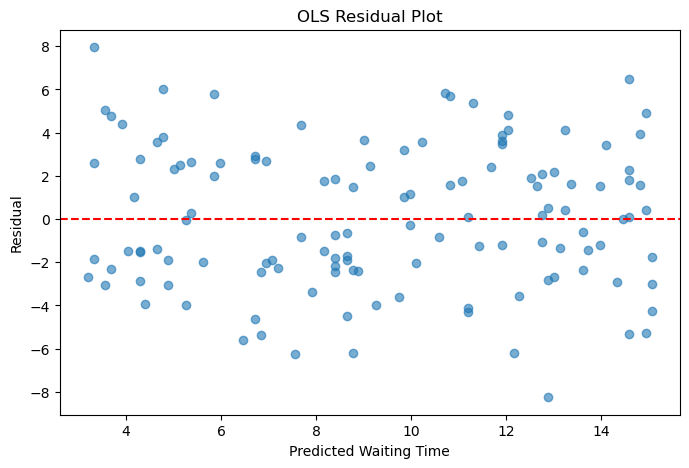

In [6]:
# Task 3 — Predictions and residuals

y_pred = ols_simple.predict(test_lin)

residuals = test_lin["wait_min"] - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Waiting Time")
plt.ylabel("Residual")
plt.title("OLS Residual Plot")
plt.show()

In [7]:
new_data = pd.DataFrame({
    "demand": [120]
})

print(ols_simple.predict(new_data))

0    11.67142
dtype: float64


In [10]:
# A new feature: Confidence interval vs. Prediction interval

prediction = ols_simple.get_prediction(
    new_data
)

display(
    prediction.summary_frame(alpha=0.05).round(3)
)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,11.671,0.212,11.254,12.089,5.106,18.237


In [11]:
# Task 4 — Evaluate the model

mae = mean_absolute_error(
    test_lin["wait_min"], y_pred
)

rmse = np.sqrt(
    mean_squared_error(test_lin["wait_min"], y_pred)
)

test_r2 = r2_score(
    test_lin["wait_min"], y_pred
)

print(f"Test MAE: {mae:.3f}")
print(f"Test RMSE: {rmse:.3f}")
print(f"Test R²: {test_r2:.3f}")

Test MAE: 2.792
Test RMSE: 3.285
Test R²: 0.546


Task 5 — Multiple Linear Regression


\begin{aligned}
\text{wait\_min}={}&\beta_0+\beta_1\text{demand}+\beta_2\text{supply}\\
&+\beta_3\text{distance}+\beta_4\text{peak}+\beta_5\text{rain}+\varepsilon
\end{aligned}


In [12]:
ols_multiple = smf.ols(
    formula="""
        wait_min ~
        demand +
        supply +
        distance_km +
        C(peak) +
        C(weather)
    """,
    data=train_lin
).fit()

print(ols_multiple.summary())

                            OLS Regression Results                            
Dep. Variable:               wait_min   R-squared:                       0.895
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     629.3
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          3.86e-178
Time:                        12:42:49   Log-Likelihood:                -695.62
No. Observations:                 375   AIC:                             1403.
Df Residuals:                     369   BIC:                             1427.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              1.9388      0

In [13]:
# Evaluate Multiple Regression

y_pred_multi = ols_multiple.predict(test_lin)

print(
    "Multiple MAE:",
    mean_absolute_error(
        test_lin["wait_min"],
        y_pred_multi
    )
)

print(
    "Multiple R²:",
    r2_score(
        test_lin["wait_min"],
        y_pred_multi
    )
)

Multiple MAE: 1.5189762273027398
Multiple R²: 0.8400206478553016
